# Day 1, Part 2: Feature analysis with Matplotlib

**Goal:** find which features relate to survival, using distributions, box plots, and a correlation heatmap. Then turn that into a first baseline with no ML at all.

Run `titanic1.ipynb` first, because this notebook reads the `titanic_clean.csv` it saves.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

if not Path("titanic_clean.csv").exists():
    raise FileNotFoundError("Run titanic1.ipynb first. It creates titanic_clean.csv.")

df = pd.read_csv("titanic_clean.csv")

# Blue = survived, orange = did not survive, violet = women, yellow = men.
SURVIVED = "#2a78d6"
DIED = "#eb6834"
WOMEN = "#6250d6"
MEN = "#eda100"
INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e4e3df"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "legend.frameon": False,
    "legend.labelcolor": MUTED,
    "font.size": 11,
})

def label_bars(ax, bars, labels, size=10.5):
    """Put a label above each bar, on a small backing so lines don't cross the text."""
    texts = ax.bar_label(bars, labels=labels, padding=3, color=INK, fontsize=size)
    for text in texts:
        text.set_bbox({"facecolor": SURFACE, "edgecolor": "none", "pad": 1})


overall = df["Survived"].mean()
print(f"{len(df)} passengers, {overall:.1%} survived")

891 passengers, 38.4% survived


## 1. Survival by sex and class

A grouped bar chart compares a rate across two categories. The dashed line is the overall rate, so you can see at a glance who beat the average.

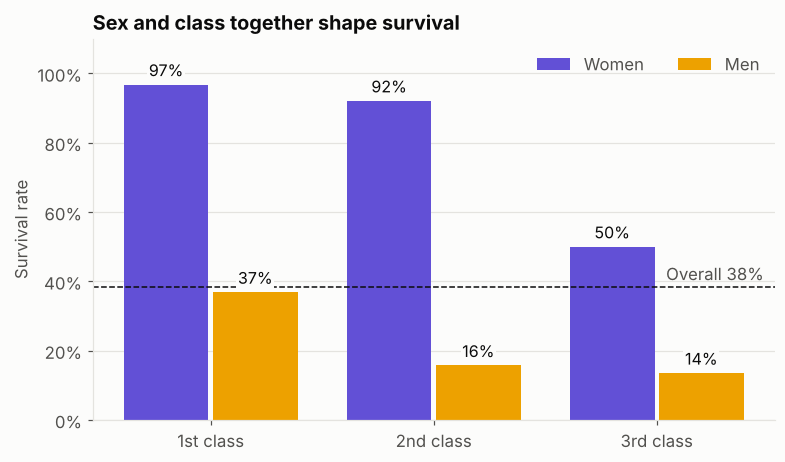

In [2]:
rates = df.pivot_table(index="Pclass", columns="Sex", values="Survived")
x = np.arange(len(rates))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
women = ax.bar(x - width / 2 - 0.01, rates["female"], width, color=WOMEN, label="Women")
men = ax.bar(x + width / 2 + 0.01, rates["male"], width, color=MEN, label="Men")
label_bars(ax, women, [f"{v:.0%}" for v in rates["female"]])
label_bars(ax, men, [f"{v:.0%}" for v in rates["male"]])

ax.axhline(overall, color=INK, linestyle="--", linewidth=1)
ax.text(2.48, overall + 0.02, f"Overall {overall:.0%}", ha="right", color=MUTED)

ax.set_xticks(x, ["1st class", "2nd class", "3rd class"])
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("Survival rate")
ax.grid(axis="x", visible=False)
ax.set_title("Sex and class together shape survival")
ax.legend(loc="upper right", ncols=2)
plt.show()

**Read it:** women in 1st and 2nd class survived at over 90%, while men in 2nd and 3rd class sit near 15%. Third-class women land at 50%, which suggests class mattered most for women.

## 2. Age distribution

Histograms show the shape of a numeric feature. We plot only **real** ages (`AgeMissing == 0`). Including our filled values would create false spikes at the group medians.

Comparing **rates** per age band is fairer than comparing raw counts, so the second panel shows survival rate by band.

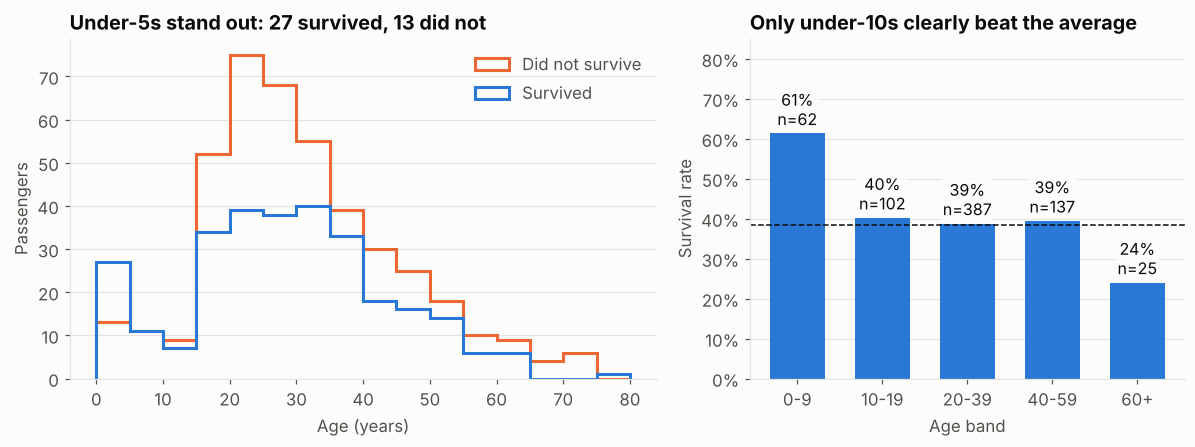

,mean,count
Age,,
0-9,0.613,62
10-19,0.402,102
20-39,0.388,387
40-59,0.394,137
60+,0.240,25


In [3]:
known = df[df["AgeMissing"] == 0]
bins = np.arange(0, 85, 5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), width_ratios=[1.35, 1])

ax1.hist(known.loc[known["Survived"] == 0, "Age"], bins=bins, histtype="step",
         color=DIED, linewidth=2, label="Did not survive")
ax1.hist(known.loc[known["Survived"] == 1, "Age"], bins=bins, histtype="step",
         color=SURVIVED, linewidth=2, label="Survived")
ax1.set_xlabel("Age (years)")
ax1.set_ylabel("Passengers")
ax1.grid(axis="x", visible=False)
ax1.set_title("Under-5s stand out: 27 survived, 13 did not")
ax1.legend()

bands = pd.cut(known["Age"], [0, 10, 20, 40, 60, 80], right=False,
               labels=["0-9", "10-19", "20-39", "40-59", "60+"])
band_stats = known.groupby(bands, observed=True)["Survived"].agg(["mean", "count"])
bars = ax2.bar(band_stats.index.astype(str), band_stats["mean"], color=SURVIVED, width=0.65)
label_bars(ax2, bars, [f"{m:.0%}\nn={c}" for m, c in zip(band_stats["mean"], band_stats["count"])])
ax2.axhline(overall, color=INK, linestyle="--", linewidth=1)
ax2.set_ylim(0, 0.85)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.set_xlabel("Age band")
ax2.set_ylabel("Survival rate")
ax2.grid(axis="x", visible=False)
ax2.set_title("Only under-10s clearly beat the average")
fig.tight_layout()
plt.show()

band_stats.round(3)

**Read it:** children under 10 are the one age group well above the overall rate. Ages 10 to 59 sit close to the average, and 60+ drops to 24%, though that band has only 25 people. So age's relationship with survival isn't a straight line. Keep that in mind when you see its near-zero correlation in section 4.

## 3. Box plots

A box plot summarises a distribution: the box spans the 25th to 75th percentile, the middle line is the median, and points beyond the whiskers are outliers. `Fare` is so skewed that the plot needs a log scale to be readable.

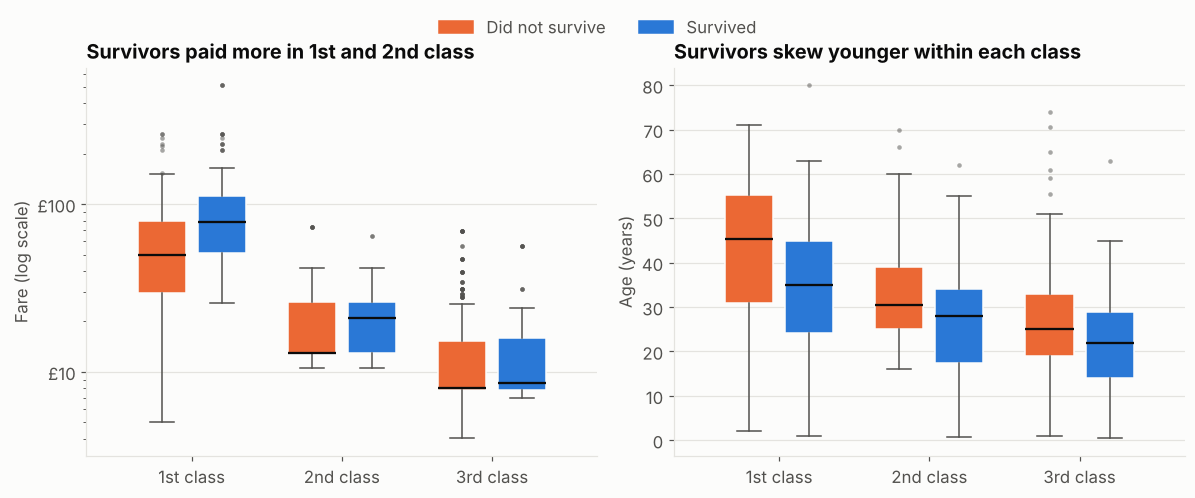

Median fare        Median age      
Survived           0      1          0     1
Pclass                                      
1              44.75  77.96      45.25  35.0
2              13.00  21.00      30.50  28.0
3               8.05   8.52      25.00  22.0

In [4]:
def split_box(ax, data, column):
    """Draw one pair of boxes per class: did not survive, then survived."""
    positions, values, colours = [], [], []
    for i, pclass in enumerate([1, 2, 3]):
        for offset, outcome, colour in [(-0.2, 0, DIED), (0.2, 1, SURVIVED)]:
            rows = data[(data["Pclass"] == pclass) & (data["Survived"] == outcome)]
            positions.append(i + offset)
            values.append(rows[column].to_numpy())
            colours.append(colour)

    box = ax.boxplot(values, positions=positions, widths=0.32, patch_artist=True,
                     medianprops={"color": INK, "linewidth": 1.5},
                     whiskerprops={"color": MUTED}, capprops={"color": MUTED},
                     flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED,
                                 "markeredgecolor": "none", "alpha": 0.5})
    for patch, colour in zip(box["boxes"], colours):
        patch.set_facecolor(colour)
        patch.set_edgecolor(SURFACE)
    ax.set_xticks(range(3), ["1st class", "2nd class", "3rd class"])
    ax.grid(axis="x", visible=False)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))

split_box(ax1, df[df["Fare"] > 0], "Fare")  # a log scale cannot show a fare of 0
ax1.set_yscale("log")
ax1.yaxis.set_major_formatter(lambda v, _: f"£{v:,.0f}")
ax1.set_ylabel("Fare (log scale)")
ax1.set_title("Survivors paid more in 1st and 2nd class")

split_box(ax2, known, "Age")  # real ages only
ax2.set_ylabel("Age (years)")
ax2.set_title("Survivors skew younger within each class")

handles = [plt.Rectangle((0, 0), 1, 1, color=DIED), plt.Rectangle((0, 0), 1, 1, color=SURVIVED)]
fig.legend(handles, ["Did not survive", "Survived"], loc="upper center", ncols=2, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
plt.show()

medians = pd.concat({
    "Median fare": df.groupby(["Pclass", "Survived"])["Fare"].median().unstack(),
    "Median age": known.groupby(["Pclass", "Survived"])["Age"].median().unstack(),
}, axis=1)
medians.round(2)

**Read it:** `Fare` and `Pclass` overlap heavily, because a higher class costs more. Even so, survivors paid more in 1st class (median £77.96 vs £44.75) and 2nd class (£21.00 vs £13.00), so `Fare` adds some information beyond class. In 3rd class the gap nearly disappears (£8.52 vs £8.05). Median age is lower for survivors in every class, by 2.5 to 10 years.

## 4. Correlation heatmap

Pearson correlation runs from -1 to +1 and measures **straight-line** relationships. Two cautions:
- A near-zero value doesn't mean a feature is useless. Age and family size are both non-linear here.
- `Pclass` is a ranking, not a true quantity, so treat its value as a rough guide.

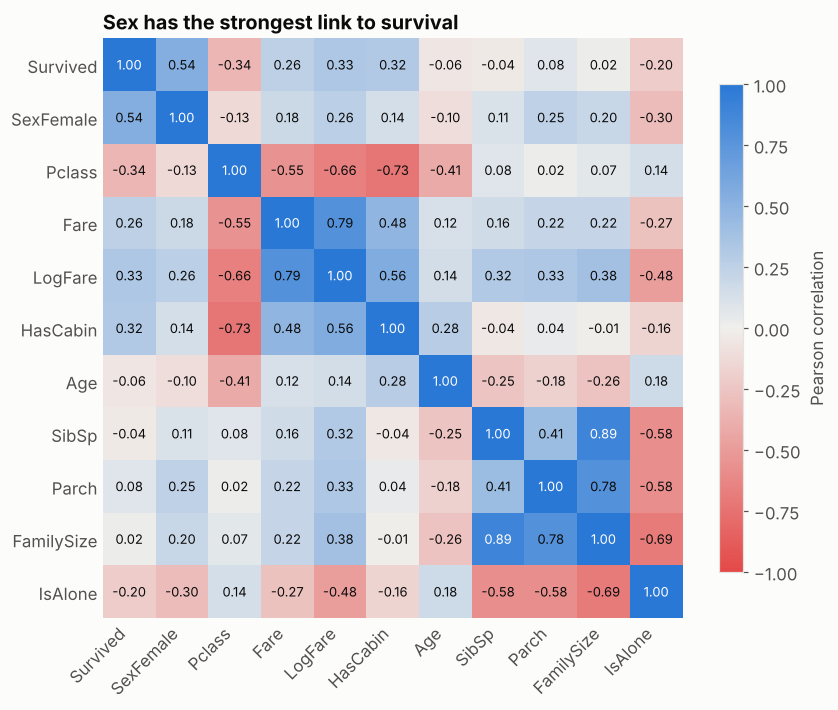

SexFemale     0.543
Pclass       -0.338
LogFare       0.330
HasCabin      0.317
Fare          0.257
IsAlone      -0.203
Parch         0.082
Age          -0.060
SibSp        -0.035
FamilySize    0.017
Name: Survived, dtype: float64

In [5]:
cols = ["Survived", "SexFemale", "Pclass", "Fare", "LogFare", "HasCabin",
        "Age", "SibSp", "Parch", "FamilySize", "IsAlone"]
corr = df[cols].corr()

cmap = LinearSegmentedColormap.from_list("polarity", ["#e34948", "#f0efec", SURVIVED])

fig, ax = plt.subplots(figsize=(8.5, 7.2))
image = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)

for i in range(len(cols)):
    for j in range(len(cols)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(value) > 0.85 else INK)

fig.colorbar(image, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Sex has the strongest link to survival")
plt.show()

corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False).round(3)

**Read it:** `SexFemale` (0.54), `Pclass` (-0.34), `LogFare` (0.33), and `HasCabin` (0.32) have the strongest links to survival. Also look for features strongly related to each other, such as `Fare`/`LogFare` and `SibSp`/`FamilySize`. They carry overlapping information, which matters for linear models.

## 5. Family size

This checks the non-linear pattern the heatmap can't show. Small groups are noisy, so the counts matter as much as the rates.

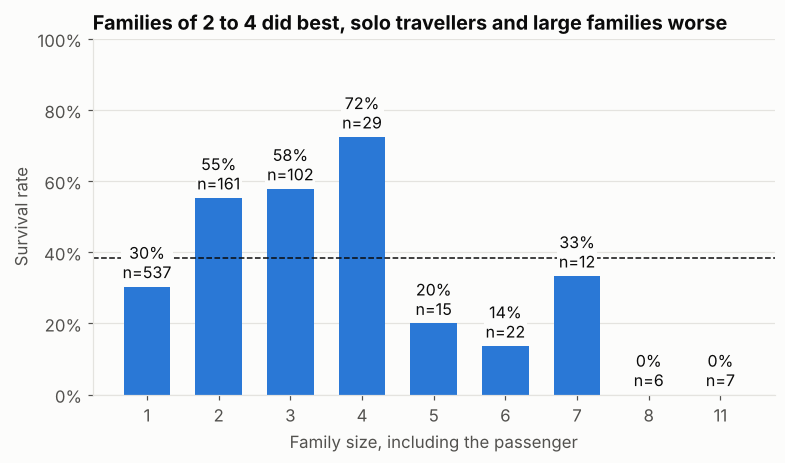

In [6]:
family = df.groupby("FamilySize")["Survived"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(family.index.astype(str), family["mean"], color=SURVIVED, width=0.65)
label_bars(ax, bars, [f"{m:.0%}\nn={c}" for m, c in zip(family["mean"], family["count"])])
ax.axhline(overall, color=INK, linestyle="--", linewidth=1)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Family size, including the passenger")
ax.set_ylabel("Survival rate")
ax.grid(axis="x", visible=False)
ax.set_title("Families of 2 to 4 did best, solo travellers and large families worse")
plt.show()

## 6. A first baseline, without any ML

A baseline is the score your model must beat. These rules are simple boolean masks, so each one is a prediction of 0 or 1 for every passenger.

In [7]:
y = df["Survived"].to_numpy()
female = df["SexFemale"].to_numpy() == 1
boy = df["Title"].to_numpy() == "Master"
upper_class = df["Pclass"].to_numpy() <= 2

rules = {
    "Everyone dies": np.zeros_like(y, dtype=bool),
    "All women survive": female,
    "Women + boys in 1st/2nd class survive": female | (boy & upper_class),
}

results = pd.Series({name: (pred.astype(int) == y).mean() for name, pred in rules.items()}, name="accuracy")
results.round(4)

Everyone dies                            0.6162
All women survive                        0.7868
Women + boys in 1st/2nd class survive    0.8002
Name: accuracy, dtype: float64

**Read it:** predicting "everyone dies" already scores 61.6%, so any accuracy has to be judged against that. One line of logic reaches 78.7%, and adding boys from 1st and 2nd class reaches 80.0%.

These scores are on the same data used to find the patterns, so they're optimistic. Real evaluation needs held-out data, which arrives with cross-validation.

## Key findings

- **Strongest signal:** sex, then class. They combine, so third-class women did far worse than other women.
- **Age:** only under-10s stand out, and the pattern isn't linear.
- **Fare:** overlaps with class but adds some signal in 1st and 2nd class.
- **Family size:** small families did best. It's a curve, not a line.
- **Benchmark for the rest of the challenge:** beat 80.0%, the best simple rule here. Day 12 of your course notes shows logistic regression at about 81.8% in 5-fold cross-validation, so plain rules get surprisingly close, although that score comes from held-out folds and these rules do not.

## Your turn

1. Change the title of the first chart to state your own main finding.
2. Make a survival-rate bar chart for `Embarked`, copying the pattern from section 5.
3. **Stretch:** write your own rule in section 6 and try to beat 80.0%. Then ask yourself whether it would hold up on new passengers.

**Stop criteria for Day 1:** you can explain every chart out loud without reading the notes, and you know why 80.0% is your number to beat.
